# Universidad de Xalapa · Actividad práctica
## Selección experimental de hiperparámetros para una MLP en PyTorch

**Propósito:** evaluar cómo influyen la tasa de aprendizaje, el número de capas/neuronas y el dropout en la convergencia y en la capacidad de generalización.

**Protocolo obligatorio:** 70 % entrenamiento / 15 % validación / 15 % prueba. **No utilizar el conjunto de prueba durante la elección de hiperparámetros.**

Al terminar deberás entregar hipótesis, código, curvas de pérdidas, matriz comparativa de seis experimentos, análisis y una sola evaluación final con el conjunto de prueba.

### 1. Preparación del entorno
Requiere `torch`, `scikit-learn`, `matplotlib`, `pandas`, `numpy`. Cuando sea necesario instala dependencias en tu propio entorno de Python.

In [1]:
import copy, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', DEVICE, '| PyTorch:', torch.__version__)

Dispositivo: cpu | PyTorch: 2.14.1


### 2. Crear los datos y evitar fuga de información

Los dos conjuntos de evaluación no se usan para calcular medias ni desviaciones del escalador. El `StandardScaler` se ajusta **exclusivamente con entrenamiento**.

Tamaños: 630 135 135


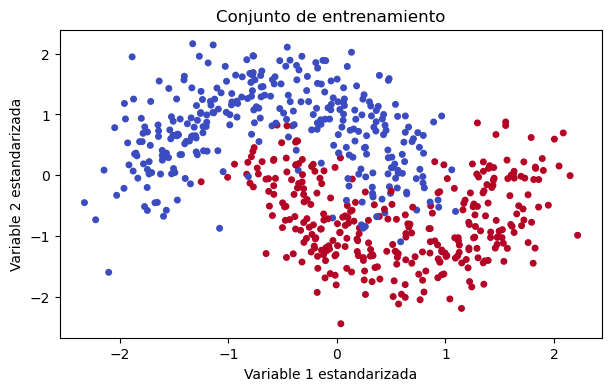

In [2]:
X, y = make_moons(n_samples=900, noise=0.22, random_state=SEED)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)

scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32)
y_val = torch.tensor(y_val.reshape(-1, 1), dtype=torch.float32)
y_test = torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32)

print('Tamaños:', len(X_train), len(X_val), len(X_test))
plt.figure(figsize=(7, 4))
plt.scatter(X_train[:,0], X_train[:,1], c=y_train.ravel(), cmap='coolwarm', s=16)
plt.title('Conjunto de entrenamiento')
plt.xlabel('Variable 1 estandarizada')
plt.ylabel('Variable 2 estandarizada')
plt.show()

### 3. Diseñar una arquitectura flexible
Cambia la lista de capas ocultas **sin modificar el método de entrenamiento**. La última capa genera un logit; no agregues Sigmoid en `forward` porque se utiliza `BCEWithLogitsLoss`.

In [3]:
class MLP(nn.Module):
    def __init__(self, hidden=(32, 16), dropout=0.0):
        super().__init__()
        layers, previous = [], 2
        for neurons in hidden:
            layers += [nn.Linear(previous, neurons), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            previous = neurons
        layers.append(nn.Linear(previous, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, X):
        return self.network(X)

model = MLP(hidden=[32, 16])
print(model)
print('Parámetros entrenables:', sum(p.numel() for p in model.parameters()))

MLP(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)
Parámetros entrenables: 641


### 4. Entrenamiento con validación y mejor checkpoint
Cada configuración se entrena por un máximo de 150 épocas. Guardamos los pesos de la menor **pérdida de validación** y después obtenemos el F1 de validación del checkpoint seleccionado. El conjunto de prueba permanece intacto.

In [4]:
BASE = dict(lr=0.001, hidden=[32, 16], dropout=0.0,
            batch_size=32, epochs=150, weight_decay=1e-4, seed=42)

def run_experiment(config):
    torch.manual_seed(config['seed'])
    model = MLP(config['hidden'], config['dropout']).to(DEVICE)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(),
                                  lr=config['lr'], weight_decay=config['weight_decay'])
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=config['batch_size'],
                        shuffle=True, generator=torch.Generator().manual_seed(config['seed']))
    history = {'train': [], 'val': []}
    best_val = float('inf')
    best_epoch, best_state = None, None
    for epoch in range(config['epochs']):
        model.train()
        total = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += float(loss) * len(xb)
        model.eval()
        with torch.no_grad():
            val_loss = float(criterion(model(X_val.to(DEVICE)), y_val.to(DEVICE)))
        history['train'].append(total / len(X_train))
        history['val'].append(val_loss)
        if val_loss < best_val:
            best_val = val_loss
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        val_logits = model(X_val.to(DEVICE))
        val_pred = (torch.sigmoid(val_logits).cpu().numpy().ravel() >= 0.5).astype(int)
    actual_val = y_val.numpy().ravel().astype(int)
    return dict(model=model, history=history,
                val_f1=f1_score(actual_val, val_pred),
                val_accuracy=accuracy_score(actual_val, val_pred),
                best_val_loss=best_val, best_epoch=best_epoch,
                params=sum(p.numel() for p in model.parameters()))

### 5. Hipótesis (completar **antes** de ejecutar)

- **H1:** Si reduzco la tasa de aprendizaje a 0.0001, espero que __________ porque __________.
- **H2:** Si aumento la tasa de aprendizaje a 0.01, espero que __________ porque __________.
- **H3:** Si aumento la profundidad de la red, espero que __________ porque __________.
- **H4:** Si agrego dropout=0.2, espero que __________ porque __________.

Recuerda: estas son hipótesis. Debes contrastarlas con los resultados; no es necesario que todas se cumplan.

### 6. Ejecutar seis configuraciones controladas
Modifica **una** condición respecto a E0. Se mantienen fijos la partición, la semilla, el batch size, el optimizador y el weight decay.

In [5]:
from pprint import pprint
experiments = {
    'E0_base': dict(BASE),
    'E1_lr_bajo': dict(BASE, lr=0.0001),
    'E2_lr_alto': dict(BASE, lr=0.01),
    'E3_pequena': dict(BASE, hidden=[8]),
    'E4_profunda': dict(BASE, hidden=[64, 32, 16]),
    'E5_dropout': dict(BASE, dropout=0.2),
}
results = {}
for name, config in experiments.items():
    results[name] = run_experiment(config)
    print(f'{name:15} F1 val={results[name]["val_f1"]:.3f}, '
          f'pérdida val={results[name]["best_val_loss"]:.3f}, '
          f'época={results[name]["best_epoch"]}, '
          f'parámetros={results[name]["params"]}')

/var/folders/8t/r8vwhxl13577bsmbfvhns66c0000gn/T/ipykernel_5445/2314069770.py:24: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  total += float(loss) * len(xb)


E0_base         F1 val=0.939, pérdida val=0.140, época=63, parámetros=641
E1_lr_bajo      F1 val=0.932, pérdida val=0.256, época=150, parámetros=641
E2_lr_alto      F1 val=0.948, pérdida val=0.124, época=18, parámetros=641
E3_pequena      F1 val=0.924, pérdida val=0.233, época=150, parámetros=33
E4_profunda     F1 val=0.947, pérdida val=0.123, época=26, parámetros=2817
E5_dropout      F1 val=0.955, pérdida val=0.153, época=67, parámetros=641


### 7. Comparar las curvas de convergencia

En cada curva identifica la velocidad de descenso, la estabilidad, la pérdida final y posibles señales de sobreajuste.

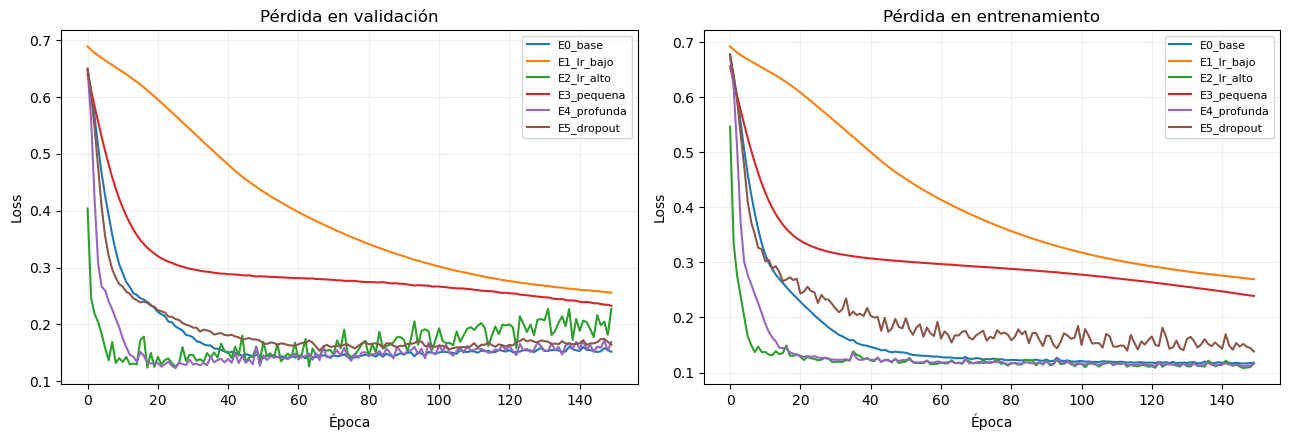

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, result in results.items():
    axes[0].plot(result['history']['val'], label=name)
    axes[1].plot(result['history']['train'], label=name)
axes[0].set(title='Pérdida en validación', xlabel='Época', ylabel='Loss')
axes[1].set(title='Pérdida en entrenamiento', xlabel='Época', ylabel='Loss')
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

### 8. Construir la matriz de resultados y seleccionar modelo

La **selección entre configuraciones utiliza exclusivamente validación**. En caso de empate de F1, se desempata por pérdida de validación. La comparación final de test debe ejecutarse una sola vez.

In [7]:
rows = []
for name, res in results.items():
    cfg = experiments[name]
    rows.append(dict(experimento=name, hidden=str(cfg['hidden']),
                     lr=cfg['lr'], dropout=cfg['dropout'],
                     F1_validacion=round(res['val_f1'], 4),
                     perdida_val=round(res['best_val_loss'], 4),
                     mejor_epoca=res['best_epoch'], parametros=res['params']))
table = pd.DataFrame(rows).sort_values(
    ['F1_validacion', 'perdida_val'], ascending=[False, True])
display(table)
chosen = table.iloc[0]['experimento']
print('Configuración seleccionada por validación:', chosen)
# Conserva el registro para el reporte:
table.to_csv('resultados_hiperparametros_UX.csv', index=False)

,experimento,hidden,lr,dropout,F1_validacion,perdida_val,mejor_epoca,parametros
5,E5_dropout,"[32, 16]",0.0010,0.2,0.9552,0.1533,67,641
2,E2_lr_alto,"[32, 16]",0.0100,0.0,0.9481,0.1236,18,641
4,E4_profunda,"[64, 32, 16]",0.0010,0.0,0.9474,0.1228,26,2817
0,E0_base,"[32, 16]",0.0010,0.0,0.9394,0.1400,63,641
1,E1_lr_bajo,"[32, 16]",0.0001,0.0,0.9323,0.2557,150,641
3,E3_pequena,[8],0.0010,0.0,0.9242,0.2326,150,33


Configuración seleccionada por validación: E5_dropout


### 9. Una sola evaluación final de prueba

**Ejecutar esta celda solo después de haber elegido el modelo en validación.** No uses estos resultados para volver a seleccionar hiperparámetros.

Accuracy prueba: 0.9704
Precision prueba: 0.9701
Recall prueba: 0.9701
F1 prueba: 0.9701


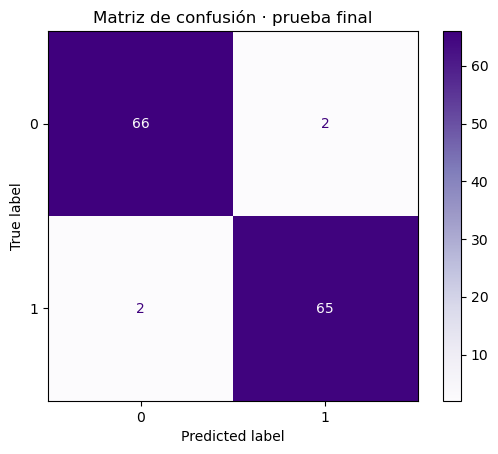

In [8]:
best_model = results[chosen]['model']
best_model.eval()
with torch.no_grad():
    logits = best_model(X_test.to(DEVICE))
    pred_test = (torch.sigmoid(logits).cpu().numpy().ravel() >= 0.5).astype(int)
actual_test = y_test.numpy().ravel().astype(int)
print('Accuracy prueba:', round(accuracy_score(actual_test, pred_test), 4))
print('Precision prueba:', round(precision_score(actual_test, pred_test, zero_division=0), 4))
print('Recall prueba:', round(recall_score(actual_test, pred_test, zero_division=0), 4))
print('F1 prueba:', round(f1_score(actual_test, pred_test, zero_division=0), 4))
ConfusionMatrixDisplay.from_predictions(actual_test, pred_test, cmap='Purples')
plt.title('Matriz de confusión · prueba final')
plt.show()

### 10. Reflexión y entrega

1. ¿Cuál hipótesis fue confirmada, rechazada o requiere más evidencia?
2. ¿Qué efectos tuvo cambiar la arquitectura en el número de parámetros?
3. ¿Qué evidencias observaste de convergencia estable, lenta o de sobreajuste?
4. ¿Por qué seleccionaste por validación y reservaste prueba?
5. ¿Qué limitaciones tiene comparar una sola semilla? ¿Cómo mejorarías el protocolo?

**Entregables:** notebook, CSV comparativo, curvas, una matriz de confusión de prueba y reporte breve con hipótesis, metodología, resultados y conclusiones.

**Rúbrica sugerida (100 puntos):** diseño experimental 20; implementación 25; evidencia 20; análisis crítico 25; comunicación 10.